# CV-Pilot tutorial: catch a worse model, survive a crash

This notebook uses **real photos and real models**, not made-up numbers. You will record a
training run, measure a pretrained object detector on 128 real photos, pin it as the model you
trust, then show that a slightly worse model is caught by a *gate* that fails your CI build.
At the end you will kill a training job with `SIGKILL` in the middle of an epoch and watch it
resume from its last checkpoint.

Every code cell is followed by a short **What this shows** note. All outputs below were produced by
actually running the notebook. It needs the internet once (about 13 MB of downloads) and takes a few
minutes on a laptop CPU. How to run it is in `notebooks/README.md`.

## 1. The problem, in three sentences

A new model can look as good as the old one on average and still be much worse on one kind of
object (say, stop signs or small objects), and nobody notices until it ships.
A long training job can also die half way (a cloud machine is taken away, the process is killed,
the disk fills up) and everything that was not saved is lost.
CV-Pilot records every run, compares a new model with the one you trust and fails your CI build
when it got worse, and saves checkpoints that survive a crash.

### Data, models and licences

* **Data:** the COCO128 subset (128 real photos from COCO train2017, with box labels) published by
  Ultralytics. It is downloaded at run time into a cache folder outside this repository and is
  **never committed or redistributed**. COCO annotations are licensed CC BY 4.0; each image keeps
  its own original Flickr licence. The conversion scripts that ship in the archive are GPL-3.0.
* **Detector:** YOLO11n, a small pretrained object detector, run through the `ultralytics` package.
  **That package is AGPL-3.0**, which is why CV-Pilot (Apache-2.0) only offers it as the optional
  extra `cvpilot[ultralytics]` and never as a core dependency. If you ship software that
  uses it, the AGPL terms apply to your combined work. The weights are downloaded at run time too.
* **Classifier:** a tiny PyTorch network that we train ourselves in this notebook on object
  crops cut out of the same photos.

### Getting ready

The next cell sets up a fresh scratch folder (so you can re-run the notebook from the top) and some small helpers. `sh(...)` runs a command, prints what it printed and its exit code, and hides the paths of this computer.

In [1]:
import contextlib
import hashlib
import json
import os
import re
import shlex
import shutil
import signal
import socket
import subprocess
import sys
import tempfile
import time
import urllib.error
import urllib.request
import warnings
import zipfile
from pathlib import Path

warnings.filterwarnings("ignore")

# Where downloads are cached. This is outside the repository and nothing in it is ever committed.
DATA = Path(
    os.environ.get("CVPILOT_NOTEBOOK_DATA") or Path(tempfile.gettempdir()) / "cvpilot-notebooks"
)
DATA.mkdir(parents=True, exist_ok=True)
# A fresh scratch folder for this run of the notebook: everything the notebook writes lives here.
WORK = Path(tempfile.mkdtemp(prefix="cvpilot-nb-"))
os.chdir(WORK)

os.environ["CVPILOT_STORE_DIR"] = "store"  # runs, metrics and evaluation results
os.environ["CVPILOT_CHECKPOINT_DIR"] = "ckpt"  # checkpoints
os.environ["CVPILOT_PROJECT"] = "coco128-yolo"  # default project of every cvpilot command
os.environ["CVPILOT_LOG_LEVEL"] = "WARNING"  # keeps this notebook's own Python calls quiet
os.environ["YOLO_VERBOSE"] = "False"  # silence the progress bars of Ultralytics
os.environ["YOLO_CONFIG_DIR"] = str(DATA / "ultralytics-config")  # keep Ultralytics settings here
(DATA / "ultralytics-config").mkdir(exist_ok=True)
TIMINGS = {}  # seconds per step, printed at the end

print("python", sys.version.split()[0], "| scratch folder: a fresh temporary directory")
print("downloads are cached in $CVPILOT_NOTEBOOK_DATA (default: <tmp>/cvpilot-notebooks)")

python 3.13.9 | scratch folder: a fresh temporary directory
downloads are cached in $CVPILOT_NOTEBOOK_DATA (default: <tmp>/cvpilot-notebooks)


**What this shows.** Everything the notebook writes goes into a temporary folder that is new on every run, with its own empty CV-Pilot store. Downloads are cached once in a separate folder so a re-run does not download again.

In [2]:
_REPLACEMENTS = sorted(
    [
        (str(WORK.resolve()), "."),
        (str(WORK), "."),
        (str(DATA.resolve()), "$CVPILOT_NOTEBOOK_DATA"),
        (str(DATA), "$CVPILOT_NOTEBOOK_DATA"),
        (str(Path.home()), "~"),
        (socket.gethostname(), "<this-computer>"),
    ],
    key=lambda pair: -len(pair[0]),
)
_OTHER_PATHS = re.compile(r"/(?:Users|home|private|var|tmp|opt)/[^\s\"',:)]+")
_QUIET_FIELDS = {"logger", "request_id", "service", "env", "@timestamp", "level", "message"}
_CLI = "import sys; sys.argv[0] = 'cvpilot'; from cvpilot.cli.app import main; main()"


def scrub(text):
    """Hide the paths and the computer name of the machine that runs this notebook."""
    for old, new in _REPLACEMENTS:
        if old:
            text = text.replace(old, new)
    return _OTHER_PATHS.sub("<path>", text)


def log_summary(line):
    """cvpilot writes one JSON object per log line on stderr; show it as one short line."""
    try:
        event = json.loads(line)
    except ValueError:
        return "stderr: " + scrub(line)
    if not isinstance(event, dict):
        return "stderr: " + scrub(line)
    fields = " ".join(
        f"{key}={scrub(str(value))[:44]}"
        for key, value in event.items()
        if key not in _QUIET_FIELDS
    )
    return f"log[{event.get('level', '?')}] {event.get('message')} {fields}"


class Result:
    def __init__(self, code, out, err):
        self.code, self.out, self.err = code, out, err

    def json(self):
        return json.loads(self.out)


def sh(
    command, *, lines=40, log_lines=8, quiet=False, keep=False, env=None, expect=None, timeout=900
):
    """Run one command, print what it printed (paths hidden) and its exit code.

    `cvpilot ...` runs the command-line tool of this Python environment. Output that is not
    JSON on stderr is shown as it is; the JSON log lines are shortened to one line each.
    The result (exit code, output) is returned only with `keep=True` or `quiet=True`.
    """
    argv = shlex.split(command)
    if argv[0] == "cvpilot":
        argv = [sys.executable, "-c", _CLI, *argv[1:]]
    elif argv[0] == "python":
        argv[0] = sys.executable
    full_env = {**os.environ, "CVPILOT_LOG_LEVEL": "INFO", **(env or {})}
    proc = subprocess.run(  # noqa: S603
        argv, capture_output=True, text=True, cwd=WORK, env=full_env, timeout=timeout, check=False
    )
    result = Result(proc.returncode, scrub(proc.stdout), scrub(proc.stderr))
    if not quiet:
        print("$", scrub(command))
        out_lines = result.out.rstrip("\n").splitlines()
        for line in out_lines[:lines]:
            print(line[:180] + (" ..." if len(line) > 180 else ""))
        if len(out_lines) > lines:
            print(f"... ({len(out_lines) - lines} more lines)")
        err_lines = [ln for ln in proc.stderr.splitlines() if ln.strip()]
        for line in err_lines[:log_lines]:
            print(log_summary(line)[:200])
        if len(err_lines) > log_lines:
            print(f"... ({len(err_lines) - log_lines} more log lines)")
        print("exit code:", proc.returncode)
    if expect is not None and proc.returncode != expect:
        raise RuntimeError(f"expected exit code {expect}, got {proc.returncode}: {command}")
    return result if (keep or quiet) else None


@contextlib.contextmanager
def timed(label):
    start = time.perf_counter()
    yield
    TIMINGS[label] = round(time.perf_counter() - start, 1)
    print(f"[{label}: {TIMINGS[label]} s]")

**What this shows.** `sh()` is a small helper: it runs a command-line tool, shows the output and the exit code (0 means success, 1 means a check failed, 2 means you used the tool wrongly). CV-Pilot also prints one JSON log line per event on a separate channel; the helper shortens each one to a single line starting with `log[...]`.

## 2. Check the install with `cvpilot doctor`

In [3]:
sh("cvpilot --version")
sh("cvpilot doctor")

$ cvpilot --version
cvpilot 0.1.0
exit code: 0


$ cvpilot doctor
ok
log[INFO] doctor_completed status=ok package_version=0.1.0 python_version=3.13.9
exit code: 0


**What this shows.** `doctor` checks that CV-Pilot can write its store and import what it needs. It prints `ok` and exits with code 0; the `log[INFO] doctor_completed` line is the structured log event for the same check.

## 3. Get the real data and the real detector

### Checking what we download

Both downloads come from GitHub release assets of `ultralytics/assets` over `https`, with a size limit and a timeout, into a temporary file that is renamed only after the check.

* **Pinned fingerprints.** The expected SHA-256 of each file is written into the next cell. A file with a different digest is deleted and the notebook stops, before anything is unpacked or loaded; a cached file that does not match is never reused. GitHub publishes no digest for these two assets (the release API returns `digest: null`), so the pins are **trust on first use**, cross-checked in two ways: the file sizes equal the sizes the release API reports (6,983,030 and 5,613,764 bytes), and downloading both files a second time gave identical digests. To update a pin after a deliberate upstream change, download the new file, review it, and replace the constant.
* **Safe unpacking.** The zip is never extracted with `extractall`. Every member is checked first (no absolute path, no `..`, no symlink or special file, at most 1000 files and 50 MB in total, compression ratio at most 20) and written into a fresh folder.
* **A `.pt` file is a pickle.** Loading a PyTorch `.pt` file can run arbitrary code, so the YOLO11n weights are loaded only after the digest check passed. The checkpoints that *we* write (the classifier in this notebook) use CV-Pilot's `safetensors` format, which contains only numbers and can never run code.

In [4]:
COCO128_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"
WEIGHTS_URL = "https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11n.pt"
# Pinned SHA-256 of every download. A file with any other digest is deleted and the notebook stops.
PINNED_SHA256 = {
    "coco128.zip": "61e5e3028863d8ffc3b81d6a514603954889f0edd5e4b44c4ce60b2da99aeb8e",
    "yolo11n.pt": "0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1",
}
MAX_DOWNLOAD_BYTES = {"coco128.zip": 20_000_000, "yolo11n.pt": 20_000_000}
ZIP_LIMITS = {"files": 1000, "bytes": 50_000_000, "ratio": 20}


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def fetch(url, name):
    """Download over https into the cache (bounded, via a temporary file) and check the SHA-256.

    A cached file with the wrong digest is deleted and fetched again; a download with the wrong
    digest is deleted and raises. Nothing is unpacked or loaded before this check passes."""
    dest = DATA / name
    if dest.exists() and sha256_of(dest) != PINNED_SHA256[name]:
        dest.unlink()  # never reuse a cached file that does not match
    if not dest.exists():
        if not url.startswith("https://"):
            raise ValueError("only https downloads are allowed")
        part = dest.with_name(name + ".part")
        try:
            with urllib.request.urlopen(url, timeout=60) as response, open(part, "wb") as out:  # noqa: S310
                total = 0
                while chunk := response.read(1 << 20):
                    total += len(chunk)
                    if total > MAX_DOWNLOAD_BYTES[name]:
                        raise RuntimeError(
                            f"{name} is larger than {MAX_DOWNLOAD_BYTES[name]} bytes"
                        )
                    out.write(chunk)
        except (urllib.error.URLError, TimeoutError, OSError) as exc:
            part.unlink(missing_ok=True)
            raise RuntimeError(
                f"Could not download {name} ({type(exc).__name__}). This notebook needs the "
                f"internet once. Download {url} yourself, put the file in the folder named by "
                "CVPILOT_NOTEBOOK_DATA (default: <tmp>/cvpilot-notebooks) and run this cell again."
            ) from None
        except RuntimeError:
            part.unlink(missing_ok=True)
            raise
        digest = sha256_of(part)
        if digest != PINNED_SHA256[name]:
            part.unlink()
            raise RuntimeError(f"{name}: SHA-256 {digest} is not the pinned {PINNED_SHA256[name]}")
        part.replace(dest)  # atomic: a half-downloaded file never has the final name
    print(
        f"{name:12s} {dest.stat().st_size / 1e6:5.1f} MB  sha256 {sha256_of(dest)}  (matches the pin)"
    )
    return dest


def safe_unzip(zip_path, target):
    """Unpack into a new folder after checking every member; never `extractall`."""
    if target.exists():
        return
    staging = Path(tempfile.mkdtemp(dir=DATA, prefix="unzip-"))
    with zipfile.ZipFile(zip_path) as archive:
        members = archive.infolist()
        too_big = sum(m.file_size for m in members) > ZIP_LIMITS["bytes"]
        if len(members) > ZIP_LIMITS["files"] or too_big:
            raise RuntimeError("the archive has too many files or is too large")
        for member in members:
            name = Path(member.filename)
            mode = member.external_attr >> 16
            if name.is_absolute() or ".." in name.parts or "\\" in member.filename:
                raise RuntimeError(f"unsafe name in the archive: {member.filename}")
            if mode and (mode & 0o170000) not in (0o100000, 0o040000):
                raise RuntimeError(f"not a plain file or folder: {member.filename}")
            ratio = member.file_size / max(member.compress_size, 1)
            if ratio > ZIP_LIMITS["ratio"]:
                raise RuntimeError(f"suspicious compression ratio: {member.filename}")
        for member in members:
            out = staging / member.filename
            if member.is_dir():
                out.mkdir(parents=True, exist_ok=True)
                continue
            out.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(member) as src, open(out, "wb") as dst:
                shutil.copyfileobj(src, dst)
    staging.rename(target)


coco_zip = fetch(COCO128_URL, "coco128.zip")
weights_path = fetch(WEIGHTS_URL, "yolo11n.pt")  # a pickle: only loaded after the check above
COCO_DIR = DATA / "coco128-unpacked"
safe_unzip(coco_zip, COCO_DIR)
COCO_ROOT = COCO_DIR / "coco128"
IMAGES = sorted((COCO_ROOT / "images" / "train2017").glob("*.jpg"))
print(f"{len(IMAGES)} images in $CVPILOT_NOTEBOOK_DATA/coco128-unpacked/coco128/images/train2017")

coco128.zip    7.0 MB  sha256 61e5e3028863d8ffc3b81d6a514603954889f0edd5e4b44c4ce60b2da99aeb8e  (matches the pin)
yolo11n.pt     5.6 MB  sha256 0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1  (matches the pin)
128 images in $CVPILOT_NOTEBOOK_DATA/coco128-unpacked/coco128/images/train2017


**What this shows.** The two files were downloaded (or found in the cache), their SHA-256 fingerprints matched the pins, and only then were they unpacked and loaded. A mismatch would have stopped the notebook with an error.

In [5]:
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
from PIL import Image

with timed("import torch and ultralytics, load YOLO11n"):
    import torch
    import ultralytics
    from ultralytics import YOLO

    ultralytics.settings.update({"sync": False})  # no usage reporting from this notebook
    MODEL = YOLO(str(weights_path))
NAMES = [MODEL.names[i] for i in range(len(MODEL.names))]
Path("classes.txt").write_text("\n".join(NAMES) + "\n")  # one class name per line, in id order
print(f"torch {torch.__version__}, ultralytics {ultralytics.__version__}, {len(NAMES)} classes")
print("device used for the detector: cpu")

[import torch and ultralytics, load YOLO11n: 0.7 s]
torch 2.14.1, ultralytics 8.4.177, 80 classes
device used for the detector: cpu


**What this shows.** The detector is loaded on the CPU. It knows the 80 classes of the COCO dataset (person, car, chair, ...); their names are saved one per line in `classes.txt`, which is the format `cvpilot eval` reads.

### The labels as a table CV-Pilot can read

`cvpilot eval` reads three things: a **ground-truth** Parquet file (the correct answers), a
**predictions** Parquet file (what the model said) and a **class list** (one name per line, in id order).

| File | Columns | Meaning |
|---|---|---|
| ground truth | `image_id`, `cls`, `x1`, `y1`, `x2`, `y2` | one row per true box: class id and the box corners in pixels |
| | `width`, `height` (optional) | image size, the same on every row of an image |
| | `iscrowd` (optional), any extra columns | extra columns can be used for *slices* (e.g. camera) |
| | a row with an empty `cls` | an image that has no objects at all |
| predictions | `image_id`, `cls`, `score`, `x1`, `y1`, `x2`, `y2` | one row per detection: class id, confidence 0..1, box corners |
| class list | one name per line | line number = class id |

COCO128 stores labels as YOLO text files (class, then box centre and size as *fractions* of the image),
so we convert them into the table above.

In [6]:
def yolo_ground_truth(root):
    """COCO128 labels are YOLO text files: `class x_center y_center width height`, all as
    fractions of the image. CV-Pilot wants pixel corners, one row per box."""
    cols = {k: [] for k in ("image_id", "cls", "x1", "y1", "x2", "y2", "width", "height")}
    for image in IMAGES:
        with Image.open(image) as handle:
            width, height = handle.size
        label = root / "labels" / "train2017" / f"{image.stem}.txt"
        lines = (
            label.read_text().splitlines() if label.exists() else []
        )  # a missing file: no objects
        boxes = [ln.split() for ln in lines if ln.strip()]
        if not boxes:  # an image with no objects: one row whose class and box are empty
            boxes = [[None] * 5]
        for cls, xc, yc, bw, bh in boxes:
            row = dict(image_id=image.stem, width=width, height=height)
            if cls is None:
                row.update(cls=None, x1=None, y1=None, x2=None, y2=None)
            else:
                xc, yc, bw, bh = (
                    float(xc) * width,
                    float(yc) * height,
                    float(bw) * width,
                    float(bh) * height,
                )
                row.update(
                    cls=int(cls), x1=xc - bw / 2, y1=yc - bh / 2, x2=xc + bw / 2, y2=yc + bh / 2
                )
            for key, value in row.items():
                cols[key].append(value)
    schema = pa.schema(
        [("image_id", pa.string()), ("cls", pa.int64())]
        + [(k, pa.float64()) for k in ("x1", "y1", "x2", "y2")]
        + [("width", pa.int64()), ("height", pa.int64())]
    )
    return pa.table(cols, schema=schema)


def show_rows(table, n=4):
    """Print the first rows of a Parquet table as plain text."""
    names = table.column_names
    print(" ".join(f"{name:>12}" for name in names))
    for row in table.slice(0, n).to_pylist():
        cells = [f"{v:.1f}" if isinstance(v, float) else str(v) for v in row.values()]
        print(" ".join(f"{cell:>12}" for cell in cells))


def detect(imgsz, *, use_cache=False):
    """Run YOLO11n on the 128 images and return detections as a table (also cached on disk)."""
    cache = (
        DATA / "predictions" / f"yolo11n-{PINNED_SHA256['yolo11n.pt'][:8]}-imgsz{imgsz}-cpu.parquet"
    )
    if use_cache and cache.exists():
        return pq.read_table(cache), 0.0, True
    start = time.perf_counter()
    cols = {k: [] for k in ("image_id", "cls", "score", "x1", "y1", "x2", "y2")}
    for lo in range(0, len(IMAGES), 16):
        batch = IMAGES[lo : lo + 16]
        # conf=0.001 keeps even very unsure boxes: mAP needs the whole precision/recall curve.
        results = MODEL.predict(
            [str(p) for p in batch],
            imgsz=imgsz,
            conf=0.001,
            iou=0.7,
            max_det=300,
            device="cpu",
            verbose=False,
        )
        for image, result in zip(batch, results, strict=True):
            boxes = result.boxes
            for (x1, y1, x2, y2), score, cls in zip(
                boxes.xyxy.numpy(), boxes.conf.numpy(), boxes.cls.numpy(), strict=True
            ):
                for key, value in zip(
                    cols,
                    (image.stem, int(cls), float(score), *map(float, (x1, y1, x2, y2))),
                    strict=True,
                ):
                    cols[key].append(value)
    table = pa.table(
        {
            "image_id": pa.array(cols["image_id"], pa.string()),
            "cls": pa.array(cols["cls"], pa.int64()),
            **{k: pa.array(cols[k], pa.float64()) for k in ("score", "x1", "y1", "x2", "y2")},
        }
    )
    cache.parent.mkdir(exist_ok=True)
    pq.write_table(table, str(cache) + ".part")
    Path(str(cache) + ".part").replace(cache)
    return table, time.perf_counter() - start, False

**What this shows.** These helpers convert the labels, print a table as plain text and run the detector. `detect()` asks YOLO11n for every detection down to a confidence of 0.001: a benchmark needs the full ranking of boxes, not only the confident ones.

In [7]:
gt = yolo_ground_truth(COCO_ROOT)
pq.write_table(gt, "gt.parquet")
has_box = [c is not None for c in gt["cls"].to_pylist()]
present = sorted({c for c in gt["cls"].to_pylist() if c is not None})
print(
    f"{len(IMAGES)} images, {sum(has_box)} labelled boxes, {len(present)} of {len(NAMES)} classes occur"
)
print(
    f"images without any object: {len(IMAGES) - len(set(i for i, h in zip(gt['image_id'].to_pylist(), has_box, strict=True) if h))}"
)
show_rows(gt)

128 images, 929 labelled boxes, 71 of 80 classes occur
images without any object: 2
    image_id          cls           x1           y1           x2           y2        width       height
000000000009           45          1.1        187.7        612.7        473.5          640          480
000000000009           45        311.7          4.3        631.0        233.0          640          480
000000000009           50        249.6        229.3        565.8        474.4          640          480
000000000009           45          0.0         13.5        434.5        388.6          640          480


**What this shows.** The 128 photos hold 929 labelled boxes of 71 different classes; the other 9 classes of the detector never occur in this set. Two images have no objects, which a ground-truth file expresses with an empty `cls`. The first rows show the pixel boxes we will compare against.

## 4. Record a run: a real training-style loss curve

First a small **real** classifier. We cut out the boxes of the most frequent classes from the photos
(*crops*, 32x32 pixels), keep at most 60 per class so that `person` does not dominate, and hold out
about one image in five for validation. This is a tiny dataset (a couple of hundred crops), so do not
expect a good accuracy; the point is a real training loop with a real loss curve to record.

In [8]:
def build_crops(gt_table, min_side=12, min_per_class=20, cap=60):
    cols = gt_table.to_pydict()
    rows = [
        i
        for i, c in enumerate(cols["cls"])
        if c is not None
        and cols["x2"][i] - cols["x1"][i] >= min_side
        and cols["y2"][i] - cols["y1"][i] >= min_side
    ]
    counts = {}
    for i in rows:
        counts[cols["cls"][i]] = counts.get(cols["cls"][i], 0) + 1
    keep = sorted((c for c, n in counts.items() if n >= min_per_class), key=lambda c: -counts[c])
    opened, taken, xs, ys, ids = {}, {}, [], [], []
    for i in rows:
        c = cols["cls"][i]
        if c not in keep or taken.get(c, 0) >= cap:
            continue
        image_id = cols["image_id"][i]
        if image_id not in opened:
            opened[image_id] = Image.open(
                COCO_ROOT / "images" / "train2017" / f"{image_id}.jpg"
            ).convert("RGB")
        box = (cols["x1"][i], cols["y1"][i], cols["x2"][i], cols["y2"][i])
        xs.append(np.asarray(opened[image_id].crop(box).resize((32, 32))))
        ys.append(keep.index(c))
        ids.append(image_id)
        taken[c] = taken.get(c, 0) + 1
    # a crop is validation data when its photo's id hash falls in 1 of 5: the same photo never
    # lands on both sides, so the classifier cannot memorise a validation photo
    import zlib

    val = np.array([zlib.crc32(s.encode()) % 5 == 0 for s in ids])
    return (
        np.stack(xs).transpose(0, 3, 1, 2).astype(np.uint8),
        np.array(ys),
        val,
        [NAMES[c] for c in keep],
    )


x, y, is_val, crop_classes = build_crops(gt)
np.savez("crops.npz", x=x, y=y, val=is_val)
print(f"{len(y)} crops, {int(is_val.sum())} held out for validation, {len(crop_classes)} classes")
print({name: int((y == k).sum()) for k, name in enumerate(crop_classes)})
print(
    f"validation: guessing the most common training class is right {np.mean(y[is_val] == np.bincount(y).argmax()):.0%} of the time, a random guess {1 / len(crop_classes):.0%}"
)

215 crops, 26 held out for validation, 7 classes
{'person': 60, 'chair': 35, 'cup': 35, 'bowl': 22, 'carrot': 22, 'teddy bear': 21, 'spoon': 20}
validation: guessing the most common training class is right 8% of the time, a random guess 14%


**What this shows.** There are only a couple of hundred crops of 7 classes, with `person` still the most common. The last line gives the numbers to beat on the validation crops: always guessing the most common class, or guessing at random. The validation set is only 26 crops, so each crop is worth about 4 points of accuracy and the accuracy numbers below jump around from epoch to epoch.

The training script below is a normal PyTorch loop with three CV-Pilot calls: `cvpilot.init(...)` starts a
run, `cvpilot.log({...}, step=...)` records a number at a step, and `run.finish()` closes the run.
It also knows how to save and resume checkpoints (`--checkpoints`); we use that in section 9. We run it as a
separate process, like a real training job, so CV-Pilot records the command that started it.

In [9]:
TRAIN_SCRIPT = r"""
# train_clf.py: a tiny image classifier trained on real COCO128 object crops.
# With --checkpoints it saves a crash-proof checkpoint every epoch and resumes by itself.
import argparse
import sys
import time

import numpy as np
import torch
from torch import nn

import cvpilot

parser = argparse.ArgumentParser()
parser.add_argument("--project", required=True)
parser.add_argument("--epochs", type=int, default=5)
parser.add_argument("--checkpoints", action="store_true", help="save and resume checkpoints")
parser.add_argument("--progress", action="store_true", help="print a line every 5 batches")
parser.add_argument("--pause-ms", type=int, default=0, help="wait this long after every batch")
args = parser.parse_args()

BATCH, PASSES = 32, 16  # one epoch = 16 shuffled passes over the (few) training crops
data = np.load("crops.npz")
images = torch.tensor(data["x"]).float() / 255
labels = torch.tensor(data["y"])
train_idx, val_idx = np.where(~data["val"])[0], np.where(data["val"])[0]
n_batches = -(-len(train_idx) * PASSES // BATCH)  # batches per epoch (rounded up)


def block(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
                         nn.ReLU(), nn.MaxPool2d(2))


torch.manual_seed(0)
model = nn.Sequential(block(3, 16), block(16, 32), block(32, 64), nn.Flatten(),
                      nn.Dropout(0.3), nn.Linear(64 * 4 * 4, int(labels.max()) + 1))
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)


def epoch_order(epoch):  # the same shuffle for the same epoch, so a resumed run sees the same data
    rng = np.random.default_rng(1000 + epoch)
    return np.concatenate([rng.permutation(train_idx) for _ in range(PASSES)])


def val_accuracy():
    model.eval()
    with torch.no_grad():
        return (model(images[val_idx]).argmax(1) == labels[val_idx]).float().mean().item()


point = None
if args.checkpoints:
    from cvpilot.ckpt import CheckpointManager, apply_rng, find_resume_point
    from cvpilot.runs import recover_run

    point = find_resume_point(args.project)  # newest run of this project that can be resumed
    if point is not None and point.needs_recover:  # its process died: mark it failed first
        recover_run(args.project, point.run_id)
run = cvpilot.init(
    args.project, task="classification", seed=0,
    config={"epochs": args.epochs, "batch": BATCH, "lr": 2e-3, "model": "3-block CNN"},
    resume_from=None if point is None else point.run_id,
)
ckpt = None
epoch0, batch0 = 0, 0  # where to start
if args.checkpoints:
    ckpt = CheckpointManager(run, every_n_steps=n_batches, keep_last=3)  # one save per epoch
    restored = ckpt.restore()  # None on a fresh start
    if restored is None:
        print("starting fresh: no checkpoint to resume from", flush=True)
    else:
        state = restored.state
        model.load_state_dict({k: torch.from_numpy(v) for k, v in state["model"].items()})
        apply_rng(state["rng"])
        epoch0, batch0 = state["dataloader_state"]["epoch"], state["dataloader_state"]["batch"] + 1
        if batch0 >= n_batches:  # the checkpoint was the last batch of an epoch: start the next one
            epoch0, batch0 = epoch0 + 1, 0
        print(f"resumed from step {restored.manifest.step} (epoch {epoch0 + 1}, batch {batch0})",
              flush=True)

for epoch in range(epoch0, args.epochs):
    order = epoch_order(epoch)
    model.train()
    for b in range(batch0 if epoch == epoch0 else 0, n_batches):
        idx = order[b * BATCH:(b + 1) * BATCH]
        xb = images[idx]
        flip = torch.rand(len(idx), generator=torch.Generator().manual_seed(epoch * 10007 + b)) < 0.5
        xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)
        loss = nn.functional.cross_entropy(model(xb), labels[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
        time.sleep(args.pause_ms / 1000)  # a stand-in for a bigger model that takes longer per batch
        step = epoch * n_batches + b + 1  # global batch counter, 1-based
        cvpilot.log({"train/loss": loss.item()}, step=step)
        if args.progress and b % 5 == 0:
            print(f"epoch {epoch + 1}/{args.epochs} batch {b}/{n_batches} loss {loss.item():.3f}",
                  flush=True)
        if ckpt is not None:
            ckpt.maybe_save(step, model=model, rng=True,
                            dataloader_state={"epoch": epoch, "batch": b})
            if ckpt.preempted():  # SIGTERM arrived: the checkpoint was just written
                print(f"preempted at epoch {epoch + 1}, batch {b}: checkpoint saved", flush=True)
                ckpt.close()
                sys.exit(0)
    acc = val_accuracy()
    model.train()
    cvpilot.log({"val/accuracy": acc}, step=epoch * n_batches + n_batches)
    print(f"epoch {epoch + 1}/{args.epochs} done: loss {loss.item():.3f} val_accuracy {acc:.2f}",
          flush=True)
run.finish()
if ckpt is not None:
    ckpt.close()
print("run", run.run_id, "finished")
"""
Path("train_clf.py").write_text(TRAIN_SCRIPT)
print(len(TRAIN_SCRIPT.splitlines()), "lines written to train_clf.py")

115 lines written to train_clf.py


**What this shows.** The script is saved as `train_clf.py` in the scratch folder. Its cell above is the whole program: nothing is hidden.

In [10]:
with timed("train classifier (5 epochs, CPU)"):
    sh("python train_clf.py --project clf-demo --epochs 5", log_lines=0)

$ python train_clf.py --project clf-demo --epochs 5
epoch 1/5 done: loss 0.128 val_accuracy 0.35
epoch 2/5 done: loss 0.106 val_accuracy 0.27
epoch 3/5 done: loss 0.015 val_accuracy 0.35
epoch 4/5 done: loss 0.009 val_accuracy 0.35
epoch 5/5 done: loss 0.007 val_accuracy 0.31
run 01M51VFFPCFG377VF1S8JNEE8R finished
... (2 more log lines)
exit code: 0
[train classifier (5 epochs, CPU): 7.2 s]


**What this shows.** Five epochs of real training: the loss (how wrong the model is, lower is better) and the accuracy on crops it never trained on. Accuracy stays modest because the data is tiny; that is expected for this demo.

In [11]:
sh("cvpilot runs list --project clf-demo")
CLF_RUN = sh("cvpilot runs list --project clf-demo --json", quiet=True).json()[0]["run_id"]
sh(f"cvpilot runs show {CLF_RUN} --project clf-demo", lines=34)

$ cvpilot runs list --project clf-demo
RUN_ID                      STATUS     STARTED                    NAME
01M51VFFPCFG377VF1S8JNEE8R  finished   2026-10-16T07:57:58.016463+00:00  python-2026-10-16
exit code: 0


$ cvpilot runs show 01M51VFFPCFG377VF1S8JNEE8R --project clf-demo
run_id: 01M51VFFPCFG377VF1S8JNEE8R
project: clf-demo
name: python-2026-10-16
status: finished
parent_run_id: -
task: classification
framework: python==3.13.9
host: <this-computer>
started_at: 2026-10-16T07:57:58.016463+00:00
ended_at: 2026-10-16T07:58:03.516041+00:00
git_commit: -
git_dirty: false
python_version: 3.13.9
cuda: -
gpu_names: -
dataset_uri: -
dataset_hash: merkle:e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
packages_lock_sha256: d42ad4cfb559c2bd76cd6984c7b2f787fc442ae238b9170326662476da93e770
seed: 0
command_line: train_clf.py --project clf-demo --epochs 5
config: {"batch": 32, "epochs": 5, "lr": 0.002, "model": "3-block CNN"}
n_points: 480
n_files: 1
steps: 1..475
exit code: 0


**What this shows.** `runs list` shows every run of a project, newest first. `runs show` shows what CV-Pilot captured for this one: the status, the settings you passed (`config`), the Python version, the exact command line and how many points were logged.

In [12]:
sh(f"cvpilot repro {CLF_RUN} --project clf-demo", lines=30)

$ cvpilot repro 01M51VFFPCFG377VF1S8JNEE8R --project clf-demo
#!/usr/bin/env bash
# Reproduction script for CV-Pilot run 01M51VFFPCFG377VF1S8JNEE8R (project clf-demo).
# Generated from the stored run record. Read it before running it.
set -euo pipefail

# 1. Code
# no git commit was recorded (the run did not start in a git repository); run the command from the original source tree

# 2. Environment (check before running)
# python: 3.13.9
# packages lock sha256: d42ad4cfb559c2bd76cd6984c7b2f787fc442ae238b9170326662476da93e770
# cuda / driver: none
# gpus: none
# seed: 0

# 3. Dataset (hash recorded at init)
# uri: none
# hash: merkle:e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855

# 4. Command (secrets were redacted at capture time; supply them via the environment)
"${PYTHON:-python3}" train_clf.py --project clf-demo --epochs 5
exit code: 0


**What this shows.** `repro` prints a shell script that would start the same job again: the recorded command, the config and the versions it ran with. That is how you answer 'how exactly was this model trained?' months later.

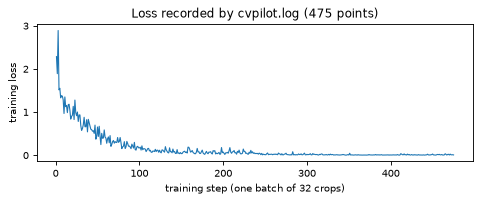

In [13]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 80, "font.size": 9})


def read_points(project, run_id, key):
    """The metric points of one run, read straight from the Parquet files of the store."""
    files = sorted(
        (Path(os.environ["CVPILOT_STORE_DIR"]) / project / "metrics" / run_id).glob("*.parquet")
    )
    points = {}
    for file in files:
        table = pq.read_table(file).to_pydict()
        for k, s, v in zip(table["key"], table["step"], table["value"], strict=True):
            if k == key:
                points[s] = v
    return sorted(points), [points[s] for s in sorted(points)]


steps, loss = read_points("clf-demo", CLF_RUN, "train/loss")
plt.figure(figsize=(6.2, 2.6))
plt.plot(steps, loss, lw=1)
plt.xlabel("training step (one batch of 32 crops)")
plt.ylabel("training loss")
plt.title(f"Loss recorded by cvpilot.log ({len(steps)} points)")
plt.tight_layout()
plt.show()

**What this shows.** The loss falls quickly then flattens: the real curve CV-Pilot stored. It is noisy because every point is one small batch.

## 5. Run a real detector and measure it, class by class

Now the main character: YOLO11n looks at the 128 photos and CV-Pilot scores it. The score is
**mAP50-95**: for every class, how well do the predicted boxes line up with the true boxes (averaged over
several strictness levels of box overlap, called IoU), then averaged over classes. 100 would be perfect.
**AP** is the same number for one class.

In [14]:
with timed("YOLO11n on 128 images at 640 px"):
    preds640, seconds, _ = detect(640)
pq.write_table(preds640, "preds_640.parquet")
print(f"{len(preds640)} detections in {seconds:.1f} s on the CPU")
show_rows(preds640)

[YOLO11n on 128 images at 640 px: 4.3 s]
16017 detections in 4.3 s on the CPU
    image_id          cls        score           x1           y1           x2           y2
000000000009           45          0.9        308.9          0.7        630.4        236.8
000000000009           50          0.8        255.0        229.6        567.5        476.0
000000000009           45          0.8          0.1        189.6        637.4        474.4
000000000009           45          0.6          1.0          7.7        433.0        393.4


**What this shows.** The detector produced thousands of candidate boxes (it is told to keep even very unsure ones). Each row is one detection: the image, the class id, a confidence `score` and the box corners in pixels. This is exactly the predictions format described above.

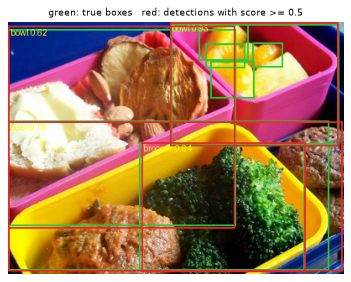

In [15]:
from PIL import ImageDraw

pick = next(i for i in IMAGES if 4 <= gt["image_id"].to_pylist().count(i.stem) <= 8)
canvas = Image.open(pick).convert("RGB")
scale = 400 / canvas.width
canvas = canvas.resize((400, int(canvas.height * scale)))
draw = ImageDraw.Draw(canvas)
for row in gt.to_pylist():
    if row["image_id"] == pick.stem and row["cls"] is not None:
        draw.rectangle(
            [row[k] * scale for k in ("x1", "y1", "x2", "y2")], outline=(40, 200, 60), width=2
        )
for row in preds640.to_pylist():
    if row["image_id"] == pick.stem and row["score"] >= 0.5:
        box = [row[k] * scale for k in ("x1", "y1", "x2", "y2")]
        draw.rectangle(box, outline=(230, 40, 40), width=2)
        draw.text(
            (box[0] + 2, box[1] + 1), f"{NAMES[row['cls']]} {row['score']:.2f}", fill=(255, 255, 0)
        )
plt.figure(figsize=(5, 3.6))
plt.imshow(canvas)
plt.axis("off")
plt.title("green: true boxes   red: detections with score >= 0.5", fontsize=8)
plt.tight_layout()
plt.show()

**What this shows.** One of the real photos with the true boxes (green) and the detections the model is confident about (red). Most agree; evaluation turns this kind of agreement, over all 128 photos and all detections, into numbers.

In [16]:
import cvpilot
from cvpilot.eval import AnnotationTable, ImageTable, PredictionTable


def to_tables(gt_table, pred_table):
    """Wrap the two Parquet tables in the objects `Run.log_eval` takes."""
    g = gt_table.to_pydict()
    sizes = {i: (w, h) for i, w, h in zip(g["image_id"], g["width"], g["height"], strict=True)}
    ids = sorted(sizes)
    images = ImageTable.from_columns(
        image_id=ids, width=[sizes[i][0] for i in ids], height=[sizes[i][1] for i in ids]
    )
    keep = [i for i, c in enumerate(g["cls"]) if c is not None]
    annotations = AnnotationTable.from_columns(
        image_id=[g["image_id"][i] for i in keep],
        class_id=[g["cls"][i] for i in keep],
        boxes=np.array([[g[k][i] for k in ("x1", "y1", "x2", "y2")] for i in keep]),
        images=images,
    )
    p = pred_table.to_pydict()
    predictions = PredictionTable.from_columns(
        image_id=p["image_id"],
        class_id=p["cls"],
        score=p["score"],
        boxes=np.column_stack([p[k] for k in ("x1", "y1", "x2", "y2")]),
    )
    return predictions, annotations


with timed("log_eval baseline"):
    run = cvpilot.init(
        "coco128-yolo",
        task="detection",
        name="yolo11n-640",
        dataset_uri=COCO_ROOT,
        config={"model": "yolo11n", "imgsz": 640, "conf": 0.001, "iou": 0.7, "device": "cpu"},
    )
    snapshot = run.log_eval(*to_tables(gt, preds640), step=0, class_names=NAMES)
    cvpilot.finish()
BASE_RUN = run.run_id
metrics = snapshot.model_dump()["metrics"]
print("run", BASE_RUN)
print(
    f"mAP50-95 = {100 * metrics['mAP50_95']:.2f}   mAP50 = {100 * metrics['mAP50']:.2f}   "
    f"(images: {snapshot.n_images})"
)

[log_eval baseline: 1.4 s]
run 01M51VFV7N35V8V5V105YA120R
mAP50-95 = 50.33   mAP50 = 67.11   (images: 128)


**What this shows.** `run.log_eval(...)` scored all detections against the ground truth and stored the result as an **evaluation snapshot** of this run: it cannot be changed afterwards. YOLO11n scores about 50 mAP50-95 on these photos. (It was trained on COCO, which includes these photos, so the number is optimistic; we use it to compare models with each other, not as a benchmark.)

In [17]:
def per_class_table(snapshot_dict, gt_table):
    g = gt_table.to_pydict()
    images_with = {}
    for i, c in zip(g["image_id"], g["cls"], strict=True):
        if c is not None:
            images_with.setdefault(NAMES[c], set()).add(i)
    rows = [
        (name, 100 * v["AP50_95"], len(images_with[name]), int(v["support"]))
        for name, v in snapshot_dict["per_class"].items()
        if v["support"] > 0
    ]
    return sorted(rows, key=lambda r: (r[1], r[0]))


rows = per_class_table(snapshot.model_dump(), gt)
print(f"{len(rows)} classes occur in the ground truth\n")
print(f"{'class':16s} {'AP50-95':>8s} {'images':>7s} {'boxes':>6s}")
for title, chosen in (("10 WORST", rows[:10]), ("10 BEST", rows[::-1][:10])):
    print(f"-- {title} --")
    for name, ap, n_images, n_boxes in chosen:
        print(f"{name:16s} {ap:8.1f} {n_images:7d} {n_boxes:6d}")

71 classes occur in the ground truth

class             AP50-95  images  boxes
-- 10 WORST --
mouse                 0.0       2      2
scissors              0.0       1      1
cell phone            3.9       5      8
handbag               6.8       9     19
baseball bat         11.0       4      4
traffic light        15.6       4     14
car                  16.3      12     46
sink                 16.5       4      6
truck                17.9       5     12
bicycle              19.4       3      6
-- 10 BEST --
hot dog             100.0       1      2
bear                100.0       1      1
zebra                97.5       2      4
microwave            93.4       3      3
airplane             92.7       5      6
train                91.1       3      3
vase                 90.1       2      2
tv                   85.0       2      2
pizza                82.2       5      5
donut                79.6       2     14


**What this shows.** The average hides a wide spread. Some classes are almost perfect while others are close to zero, and the worst ones have very few examples (one to three images), so one missed box moves them a lot. Keep this in mind when you set per-class limits: classes with few examples are noisy.

### Do the numbers agree with other tools?

We should not just trust our own number. Below, the **same** detections are scored by `pycocotools`
(the reference COCO evaluation code, which CV-Pilot is tested against), and the same model on the
same photos is scored by Ultralytics' own `val()` command. The Ultralytics run uses its own image
preparation and its own scoring code, so we expect close numbers, not identical ones.

In [18]:
def pycocotools_map(gt_table, pred_table):
    import io

    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    g = gt_table.to_pydict()
    sizes = {i: (w, h) for i, w, h in zip(g["image_id"], g["width"], g["height"], strict=True)}
    index = {name: n for n, name in enumerate(sorted(sizes), 1)}
    annotations = []
    for i, c in enumerate(g["cls"]):
        if c is not None:
            w, h = g["x2"][i] - g["x1"][i], g["y2"][i] - g["y1"][i]
            annotations.append(
                dict(
                    id=len(annotations) + 1,
                    image_id=index[g["image_id"][i]],
                    category_id=c,
                    bbox=[g["x1"][i], g["y1"][i], w, h],
                    area=w * h,
                    iscrowd=0,
                )
            )
    truth = COCO()
    truth.dataset = dict(
        images=[dict(id=index[i], width=sizes[i][0], height=sizes[i][1]) for i in sizes],
        annotations=annotations,
        categories=[dict(id=n, name=name) for n, name in enumerate(NAMES)],
    )
    with contextlib.redirect_stdout(io.StringIO()):
        truth.createIndex()
        p = pred_table.to_pydict()
        results = [
            dict(image_id=index[i], category_id=c, score=s, bbox=[x1, y1, x2 - x1, y2 - y1])
            for i, c, s, x1, y1, x2, y2 in zip(
                p["image_id"], p["cls"], p["score"], p["x1"], p["y1"], p["x2"], p["y2"], strict=True
            )
        ]
        found = truth.loadRes(results)
        scorer = COCOeval(truth, found, "bbox")
        scorer.evaluate()
        scorer.accumulate()
        scorer.summarize()
    return float(scorer.stats[0])


def ultralytics_map(imgsz):
    """Ultralytics' own validation of the same weights on the same 128 photos."""
    yaml = Path("coco128.yaml")
    yaml.write_text(
        f"path: {COCO_ROOT}\ntrain: images/train2017\nval: images/train2017\nnames:\n"
        + "".join(f"  {i}: {n}\n" for i, n in enumerate(NAMES))
    )
    result = MODEL.val(
        data=str(yaml),
        imgsz=imgsz,
        batch=16,
        conf=0.001,
        iou=0.7,
        device="cpu",
        plots=False,
        verbose=False,
        project=str(WORK / "ultralytics-val"),
        exist_ok=True,
    )
    return float(result.box.map)


with timed("cross-checks (pycocotools, Ultralytics val)"):
    try:
        coco_map = 100 * pycocotools_map(gt, preds640)
    except ImportError:
        coco_map = None
    ultra_map = 100 * ultralytics_map(640)
ours = 100 * metrics["mAP50_95"]
print(f"CV-Pilot  (log_eval, 640 px)           : {ours:6.2f}")
print(
    "pycocotools (same detections)          : "
    + (
        f"{coco_map:6.2f}"
        if coco_map is not None
        else "not installed (it is a dev dependency of CV-Pilot)"
    )
)
print(f"Ultralytics val() (its own pipeline)   : {ultra_map:6.2f}")
print(f"difference CV-Pilot - Ultralytics      : {ours - ultra_map:+6.2f} points")

[cross-checks (pycocotools, Ultralytics val): 3.8 s]
CV-Pilot  (log_eval, 640 px)           :  50.33
pycocotools (same detections)          :  50.33
Ultralytics val() (its own pipeline)   :  50.46
difference CV-Pilot - Ultralytics      :  -0.13 points


**What this shows.** On the same detections CV-Pilot and `pycocotools` give the same number, and CV-Pilot is within a fraction of a point of Ultralytics' own `val()`. We measured this gap; we did not track down its exact cause, and we do not claim the two tools are identical. A section below repeats the comparison at a smaller input size, where the gap is larger.

## 6. Pin the baseline: the model you trust

In [19]:
sh(f"cvpilot baseline set prod {BASE_RUN}")
sh("cvpilot baseline list")

$ cvpilot baseline set prod 01M51VFV7N35V8V5V105YA120R
pinned prod: run 01M51VFV7N35V8V5V105YA120R eval_set b720c966844f step 0
log[INFO] baseline_set project=coco128-yolo tag=prod run_id=01M51VFV7N35V8V5V105YA120R eval_set_hash=b720c966844f83652fb422c7aac5587ae4a340258c5e step=0 replaced=False
exit code: 0


$ cvpilot baseline list
TAG                               RUN_ID                           STEP  EVAL_SET      PINNED_AT
prod                              01M51VFV7N35V8V5V105YA120R          0  b720c966844f  2026-10-16T07:58:15.114231+00:00
exit code: 0


**What this shows.** `baseline set prod RUN` pins the run's evaluation under the name `prod`. From now on "is this new model worse than prod?" has a definite answer. Pins are append-only: replacing one needs `--replace` and keeps the old one in the history.

## 7. A worse candidate: same model, smaller input

To get a believable worse model without training anything new, we run the **same** YOLO11n but feed it
smaller pictures. Cheaper to run, usually a bit less accurate, and the loss is not evenly spread. We try
two candidates, and a third that is identical to the baseline:

* **A** is the baseline again, evaluated as a new run (it must pass),
* **B** uses 480 px instead of 640 px (a small drop on average),
* **C** uses 160 px (a big drop).

I first tried 160 px and the average fell by 32 points, which any gate would catch; 480 px is the
interesting case, so both are shown.

In [20]:
def new_run(name, config):
    """An empty, finished run to attach an evaluation to (the same thing a CI job would do)."""
    run = cvpilot.init("coco128-yolo", task="detection", name=name, config=config)
    cvpilot.finish()
    return run.run_id


CAND = {}
PREDS = {}
for label, size, reuse in (("A", 640, True), ("B", 480, False), ("C", 160, False)):
    if reuse:
        table = preds640
    else:
        with timed(f"YOLO11n at {size} px"):
            table, seconds, _ = detect(size)
    PREDS[label] = table
    pq.write_table(table, f"preds_{label}.parquet")
    CAND[label] = new_run(
        f"yolo11n-{size}-{label}", {"model": "yolo11n", "imgsz": size, "device": "cpu"}
    )
    result = sh(
        f"cvpilot eval {CAND[label]} --preds preds_{label}.parquet --gts gt.parquet "
        f"--classes classes.txt --allow-closed --json",
        quiet=True,
        expect=0,
    )
    snap = result.json()
    CAND[label + "_snapshot"] = snap
    print(
        f"candidate {label} ({size} px): run {CAND[label]}  mAP50-95 = {100 * snap['metrics']['mAP50_95']:.2f}"
        f"  ({len(table)} detections)"
    )

candidate A (640 px): run 01M51VG0VZA69QG0WTBA6KX16V  mAP50-95 = 50.33  (16017 detections)


[YOLO11n at 480 px: 2.1 s]


candidate B (480 px): run 01M51VG4AF0116KZJFNG9JKKK7  mAP50-95 = 46.40  (14304 detections)


[YOLO11n at 160 px: 0.5 s]


candidate C (160 px): run 01M51VG69F39S6D67FR95T7R80  mAP50-95 = 18.19  (7012 detections)


**What this shows.** Three more runs, each with its own stored evaluation made by the command line `cvpilot eval`. Smaller input pictures give a lower score: the average already drops for B and collapses for C. Candidate A has the same detections as the baseline, so it has the same score.

In [21]:
with timed("cross-check at 480 px"):
    coco480 = 100 * pycocotools_map(gt, PREDS["B"])
    ultra480 = 100 * ultralytics_map(480)
mine480 = 100 * CAND["B_snapshot"]["metrics"]["mAP50_95"]
print(
    f"CV-Pilot (eval, 480 px) {mine480:6.2f} | pycocotools {coco480:6.2f} | Ultralytics val() {ultra480:6.2f}"
)
print(f"difference CV-Pilot - Ultralytics: {mine480 - ultra480:+.2f} points")

[cross-check at 480 px: 2.5 s]
CV-Pilot (eval, 480 px)  46.40 | pycocotools  46.40 | Ultralytics val()  47.83
difference CV-Pilot - Ultralytics: -1.44 points


**What this shows.** The same three-way check at 480 px. CV-Pilot and `pycocotools` still agree on the same detections, but Ultralytics' own number is higher by more than a point. We did not investigate why; `val()` prepares and batches the images itself, which is one possible reason but not something we verified. The conclusion we can support is: CV-Pilot scores the detections it is given like the COCO reference code; it does not reproduce Ultralytics' pipeline exactly.

In [22]:
sh(f"cvpilot compare {CAND['B']} --baseline tag:prod", lines=32, log_lines=2)

$ cvpilot compare 01M51VG4AF0116KZJFNG9JKKK7 --baseline tag:prod
  candidate: run 01M51VG4AF0116KZJFNG9JKKK7 step 0 eval_set b720c966844f n_images 128
  baseline: run 01M51VFV7N35V8V5V105YA120R step 0 eval_set b720c966844f n_images 128
  unit: delta in points on the 0..100 scale (candidate - baseline)
  mAP50_95: 0.5033 -> 0.4640 (-3.93 points, intervals overlap)
  mAP50: 0.6711 -> 0.6110 (-6.01 points, intervals overlap)
  mAP75: 0.5542 -> 0.4942 (-6.00 points, no intervals)
  mAP_small: 0.2028 -> 0.1493 (-5.35 points, no intervals)
  mAP_medium: 0.4577 -> 0.4105 (-4.72 points, no intervals)
  mAP_large: 0.7054 -> 0.7035 (-0.19 points, no intervals)
  AR1: 0.3782 -> 0.3632 (-1.49 points, no intervals)
  AR10: 0.5911 -> 0.5399 (-5.12 points, no intervals)
  AR100: 0.6315 -> 0.5759 (-5.56 points, intervals overlap)
  AR_small: 0.3118 -> 0.2399 (-7.19 points, no intervals)
  AR_medium: 0.6351 -> 0.5555 (-7.96 points, no intervals)
  AR_large: 0.7878 -> 0.7662 (-2.16 points, no intervals)

**What this shows.** `compare` lists every headline number as *baseline -> candidate* with the change in points, then the **classes that dropped most, worst first**, then which boxes switched meaning (`person -> background` means a person that used to be found and is now missed). B loses about 4 points on average, but individual classes lose 20 to 40 points.

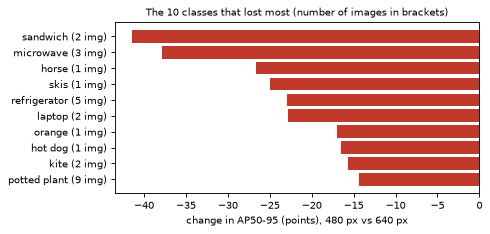

In [23]:
base_rows = {n: ap for n, ap, _, _ in per_class_table(snapshot.model_dump(), gt)}
cand_rows = {n: (ap, ni) for n, ap, ni, _ in per_class_table(CAND["B_snapshot"], gt)}
deltas = sorted((cand_rows[n][0] - base_rows[n], n, cand_rows[n][1]) for n in cand_rows)[:10]
plt.figure(figsize=(6.2, 3.0))
plt.barh(
    [f"{n} ({k} img)" for _, n, k in deltas][::-1], [d for d, _, _ in deltas][::-1], color="#c0392b"
)
plt.xlabel("change in AP50-95 (points), 480 px vs 640 px")
plt.title("The 10 classes that lost most (number of images in brackets)", fontsize=9)
plt.tight_layout()
plt.show()

**What this shows.** The same information as a picture. Most of the classes that lose the most have very few images, so some of this is luck of the draw, but a few (for example `refrigerator`, `laptop`) are the kind of loss you want a gate to flag.

### Gates: the average passes, the classes fail

In [24]:
sh(f"cvpilot gate {CAND['B']} --baseline tag:prod --max-drop mAP50_95=5", log_lines=2, expect=0)

$ cvpilot gate 01M51VG4AF0116KZJFNG9JKKK7 --baseline tag:prod --max-drop mAP50_95=5
gate: PASS (1 checks, 0 slices skipped) run 01M51VG4AF0116KZJFNG9JKKK7 step 0 vs baseline tag:prod
log[INFO] gate_passed run_id=01M51VG4AF0116KZJFNG9JKKK7 baseline_tag=prod n_violations=0
exit code: 0


**What this shows.** A gate with only an overall limit ("mAP50-95 may drop by at most 5 points") **passes** candidate B: it lost about 4 points. Exit code 0 means CI would go green.

In [25]:
sh(
    f"cvpilot gate {CAND['B']} --baseline tag:prod --max-drop mAP50_95=5 --per-class-max-drop AP50_95=20",
    log_lines=2,
    expect=1,
)

$ cvpilot gate 01M51VG4AF0116KZJFNG9JKKK7 --baseline tag:prod --max-drop mAP50_95=5 --per-class-max-drop AP50_95=20
gate: FAIL (6 violations, worst: [class_drop] sandwich) run 01M51VG4AF0116KZJFNG9JKKK7 step 0 vs baseline tag:prod
  - [class_drop] sandwich: AP50_95 of class dropped 41.42 points (limit 20)
  - [class_drop] microwave: AP50_95 of class dropped 37.82 points (limit 20)
  - [class_drop] horse: AP50_95 of class dropped 26.67 points (limit 20)
  - [class_drop] skis: AP50_95 of class dropped 25.00 points (limit 20)
  - [class_drop] refrigerator: AP50_95 of class dropped 22.99 points (limit 20)
  - [class_drop] laptop: AP50_95 of class dropped 22.77 points (limit 20)
log[ERROR] gate_failed run_id=01M51VG4AF0116KZJFNG9JKKK7 baseline_tag=prod n_violations=6 worst_metric=sandwich worst_kind=class_drop worst_delta=-41.419141914
exit code: 1


**What this shows.** The same candidate with an extra **per-class** limit ("no class may drop by more than 20 points") **fails** with exit code 1 and names every class that broke the limit. This is the case the average hid. Only the two together protect you: a model can pass one and fail the other.

In [26]:
sh(
    f"cvpilot gate {CAND['A']} --baseline tag:prod --max-drop mAP50_95=5 --per-class-max-drop AP50_95=20",
    log_lines=2,
    expect=0,
)
sh(
    f"cvpilot gate {CAND['C']} --baseline tag:prod --max-drop mAP50_95=5 --per-class-max-drop AP50_95=20",
    lines=6,
    log_lines=2,
    expect=1,
)

$ cvpilot gate 01M51VG0VZA69QG0WTBA6KX16V --baseline tag:prod --max-drop mAP50_95=5 --per-class-max-drop AP50_95=20
gate: PASS (72 checks, 0 slices skipped) run 01M51VG0VZA69QG0WTBA6KX16V step 0 vs baseline tag:prod
log[INFO] gate_passed run_id=01M51VG0VZA69QG0WTBA6KX16V baseline_tag=prod n_violations=0
exit code: 0


$ cvpilot gate 01M51VG69F39S6D67FR95T7R80 --baseline tag:prod --max-drop mAP50_95=5 --per-class-max-drop AP50_95=20
gate: FAIL (52 violations, worst: [class_drop] stop sign) run 01M51VG69F39S6D67FR95T7R80 step 0 vs baseline tag:prod
  - [class_drop] stop sign: AP50_95 of class dropped 75.05 points (limit 20)
  - [class_drop] vase: AP50_95 of class dropped 74.81 points (limit 20)
  - [class_drop] skis: AP50_95 of class dropped 70.00 points (limit 20)
  - [class_drop] train: AP50_95 of class dropped 66.66 points (limit 20)
  - [class_drop] bird: AP50_95 of class dropped 60.97 points (limit 20)
... (47 more lines)
log[ERROR] gate_failed run_id=01M51VG69F39S6D67FR95T7R80 baseline_tag=prod n_violations=52 worst_metric=stop sign worst_kind=class_drop worst_delta=-75.04950495
exit code: 1


**What this shows.** Candidate A, identical to the baseline, **passes** (exit 0) with 72 checks (one per class that occurs plus the overall one). The 160 px candidate C fails already on the overall number and also on a very long list of classes (only the first lines are shown).

## 8. The same gate in CI

On every pull request you want a machine, not a person, to run this. This is the GitHub Action example from the
CV-Pilot docs (shown, **not run here**). The important design idea: the gate runs with the *trusted* code and
baseline from the base branch and only *evaluates* the pull request's predictions; a pull request must not be able to change the
rules it is judged by.

```yaml
name: gate
on: pull_request # never pull_request_target
permissions:
  contents: read
jobs:
  gate:
    runs-on: ubuntu-latest
    steps:
      # The base commit is trusted code: its action.yml, its CI scripts, its ground truth.
      - uses: actions/checkout@11bd71901bbe5b1630ceea73d27597364c9af683 # v4.2.2
        with:
          ref: ${{ github.event.pull_request.base.sha }}
          persist-credentials: false
      - uses: actions/setup-python@a26af69be951a213d495a4c3e4e4022e16d87065 # v5.6.0
        with:
          python-version: "3.12"
      # A pinned release with hashes (pip-compile --generate-hashes), never the pull request.
      - run: python -m pip install --require-hashes --no-deps -r ci/cvpilot-requirements.txt
      # ci/make_candidate.py (from the base branch) copies the protected baseline store and runs
      # cvpilot eval on the pull request's predictions with the trusted ground truth and
      # --git-commit; it writes run-id=<ULID> to $GITHUB_OUTPUT.
      - id: candidate
        run: python ci/make_candidate.py
      - uses: ./
        with:
          run-id: ${{ steps.candidate.outputs.run-id }}
          baseline: tag:prod
          project: demo
          store-dir: ci-store
          recompute: "true"
          gt: ci/ground-truth.parquet
          classes: ci/classes.txt
          require-commit: ${{ github.event.pull_request.head.sha }}
          expect-baseline-chain: ${{ vars.CVPILOT_BASELINE_CHAIN }}
          max-drop: |
            mAP50_95=0.5
          slice-max-drop: |
            camera=*:1.5
          min-images: "30"
```

When the gate exits 1, the check on the pull request turns red and the step summary lists the violations, just as in the cells above.
`recompute` makes the gate re-score the stored predictions itself instead of trusting numbers in the store.
See `docs/guide/gating-ci.md` for the full list of conditions.

## 9. Sending metrics to a tracker (MLflow, W&B, Trackio)

`cvpilot.init(..., forward_to=["mlflow"])` also sends every logged number to the tracker you already use. We do **not**
run this here, on purpose: the forwarder accepts only an `https` endpoint (plain `http` only with `CVPILOT_ENV=dev`, and a
`file:` folder such as a local MLflow store is not accepted at all), refuses credentials inside URLs and refuses to switch TLS
verification off. A local, file-based MLflow would need us to weaken one of those rules, so the demo is skipped rather than
loosening a safety check. The tracker's token stays in the tracker's own environment variables (for example `MLFLOW_TRACKING_TOKEN`),
never in CV-Pilot. A tracker that is down or slow never blocks or crashes your training loop.

## 10. Crash-proof checkpoints

A checkpoint is a snapshot of everything needed to continue training: the model weights, the position in the data and
the random-number state. `CheckpointManager` saves them so that a kill at *any* instant leaves either the previous
checkpoint or a complete new one, never a half-written file, and it only loads a checkpoint after checking its size and
fingerprint.

The experiment: start the training script from section 4 with `--checkpoints` (one save per epoch) in its own process, wait until it is
in the middle of epoch 3 of 6, and kill it with `SIGKILL`, the signal that gives a process no chance to react.

In [27]:
def start_training(project, epochs=6):
    return subprocess.Popen(  # noqa: S603
        [
            sys.executable,
            "train_clf.py",
            "--project",
            project,
            "--epochs",
            str(epochs),
            "--checkpoints",
            "--progress",
            "--pause-ms",
            "20",
        ],
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True,
        cwd=WORK,
        env={**os.environ, "CVPILOT_LOG_LEVEL": "INFO"},
    )


def watch(proc, until, sig):
    """Echo the job's progress lines; when `until(line)` is true send it the signal `sig`."""
    seen = []
    for line in proc.stdout:
        seen.append(line.rstrip())
        if until(line):
            proc.send_signal(sig)
            break
    proc.wait()
    return seen, proc.stderr.read()


def at(epoch, batch):
    key = f"epoch {epoch}/"
    return lambda line: (
        line.startswith(key)
        and " batch " in line
        and int(line.split("batch ")[1].split("/")[0]) >= batch
    )


with timed("training job killed with SIGKILL"):
    kill_seen, _ = watch(start_training("clf-kill"), at(3, 60), signal.SIGKILL)
print("\n".join(kill_seen[-4:]))
print("the process was killed: it never printed 'finished' and had no chance to save anything")

[training job killed with SIGKILL: 11.3 s]
epoch 3/6 batch 45/95 loss 0.043
epoch 3/6 batch 50/95 loss 0.042
epoch 3/6 batch 55/95 loss 0.042
epoch 3/6 batch 60/95 loss 0.011
the process was killed: it never printed 'finished' and had no chance to save anything


**What this shows.** The job ran epochs 1 and 2 completely, got 60 batches into epoch 3, and was killed there. Python code could not run any clean-up; whatever is on disk is what a real crash would leave.

In [28]:
sh("cvpilot runs list --project clf-kill")
sh("cvpilot ckpt list ckpt --project clf-kill")
sh("cvpilot ckpt verify ckpt --project clf-kill", log_lines=0)

$ cvpilot runs list --project clf-kill
RUN_ID                      STATUS     STARTED                    NAME
01M51VGD569WNPKKYV5D0F93HK  running    2026-10-16T07:58:28.185319+00:00  python-2026-10-16
exit code: 0


$ cvpilot ckpt list ckpt --project clf-kill
01M51VGD569WNPKKYV5D0F93HK  last  000000190  valid    anchored
01M51VGD569WNPKKYV5D0F93HK  last  000000095  valid    anchored
exit code: 0


$ cvpilot ckpt verify ckpt --project clf-kill
01M51VGD569WNPKKYV5D0F93HK  last  000000190  valid    anchored
01M51VGD569WNPKKYV5D0F93HK  last  000000095  valid    anchored
... (2 more log lines)
exit code: 0


**What this shows.** The store is intact but the run is still marked `running` (nobody told it the process died). `ckpt list` shows the two checkpoints written at the end of epoch 1 and epoch 2 (a checkpoint is named by the training step it was taken at). `ckpt verify` re-reads every file and checks its size and fingerprint: both are `valid`, with trust level `anchored` (the fingerprint is also recorded in the run store, not only next to the file).

Now restart the script (without the artificial pause). `find_resume_point` finds the newest run that can be continued and its checkpoint; because that run was left `running` by a dead process, the script first marks it `failed` with `recover_run`, then starts a new run that continues it.

In [29]:
with timed("resume and finish training"):
    sh(
        "python train_clf.py --project clf-kill --epochs 6 --checkpoints",
        lines=12,
        log_lines=3,
        expect=0,
    )
sh("cvpilot runs list --project clf-kill", log_lines=0)

$ python train_clf.py --project clf-kill --epochs 6 --checkpoints
resumed from step 190 (epoch 3, batch 0)
epoch 3/6 done: loss 0.023 val_accuracy 0.38
epoch 4/6 done: loss 0.020 val_accuracy 0.27
epoch 5/6 done: loss 0.038 val_accuracy 0.35
epoch 6/6 done: loss 0.021 val_accuracy 0.31
run 01M51VGS46FMP55XF6S3Q5QWZF finished
log[INFO] resume_point_selected run_id=01M51VGD569WNPKKYV5D0F93HK checkpoint_run_id=01M51VGD569WNPKKYV5D0F93HK step=190 status=running trust_level=anchored reason=newest resumable run
log[INFO] run_finished run_id=01M51VGD569WNPKKYV5D0F93HK project=clf-kill status=failed n_points=208
log[INFO] run_started run_id=01M51VGS46FMP55XF6S3Q5QWZF project=clf-kill status=resumed task=classification parent_run_id=01M51VGD569WNPKKYV5D0F93HK
... (11 more log lines)
exit code: 0
[resume and finish training: 6.1 s]


$ cvpilot runs list --project clf-kill
RUN_ID                      STATUS     STARTED                    NAME
01M51VGS46FMP55XF6S3Q5QWZF  finished   2026-10-16T07:58:40.441679+00:00  python-2026-10-16
01M51VGD569WNPKKYV5D0F93HK  failed     2026-10-16T07:58:28.185319+00:00  python-2026-10-16
exit code: 0


**What this shows.** The restarted job printed `resumed from step ... (epoch 3, batch 0)`: it continued from the end of epoch 2 and redid the half epoch that was lost, then finished epochs 3 to 6. The killed run is now `failed`, the new run `finished`, and the new run records the killed one as its parent (`parent_run_id`).

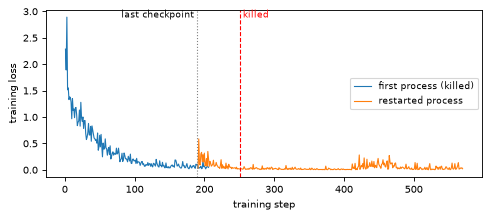

first process: steps 1..206 reached the disk (it was killed at step 251); restart: steps 191..570


In [30]:
runs = sh("cvpilot runs list --project clf-kill --json", quiet=True).json()
killed = next(r for r in runs if r["status"] == "failed")["run_id"]
second = next(r for r in runs if r["status"] == "finished")["run_id"]
s1, l1 = read_points("clf-kill", killed, "train/loss")
s2, l2 = read_points("clf-kill", second, "train/loss")
last_line = kill_seen[-1]  # for example "epoch 3/6 batch 40/95 loss 0.150"
epoch_no = int(last_line.split()[1].split("/")[0])
batch_no, per_epoch = map(int, last_line.split("batch ")[1].split()[0].split("/"))
kill_step = (epoch_no - 1) * per_epoch + batch_no + 1
ckpt_step = (epoch_no - 1) * per_epoch  # the end of the previous epoch
plt.figure(figsize=(6.2, 2.8))
plt.plot(s1, l1, lw=1, label="first process (killed)")
plt.plot(s2, l2, lw=1, label="restarted process")
plt.axvline(ckpt_step, color="grey", ls=":", lw=1)
plt.axvline(kill_step, color="red", ls="--", lw=1)
plt.text(ckpt_step, plt.ylim()[1], "last checkpoint ", fontsize=8, ha="right", va="top")
plt.text(kill_step, plt.ylim()[1], " killed", fontsize=8, color="red", va="top")
plt.xlabel("training step")
plt.ylabel("training loss")
plt.legend(fontsize=8, loc="center right")
plt.tight_layout()
plt.show()
print(
    f"first process: steps {s1[0]}..{s1[-1]} reached the disk (it was killed at step {kill_step}); restart: steps {s2[0]}..{s2[-1]}"
)

**What this shows.** One loss curve that continues across the kill. The red dashed line is where the first process was killed and the dotted line is the checkpoint it resumed from, so the steps between the two lines were trained twice, once by each process. That is the price of a crash: at most the work since the last checkpoint. The first curve may stop a little before the red line: metric points are buffered in memory and written to disk every 2 seconds, so a `SIGKILL` loses the last few points that were not written yet, but never the checkpoint.

Preemption is the polite version of the same problem: a cloud scheduler sends `SIGTERM` ("please stop, you have 30 seconds"). `CheckpointManager` catches it, saves immediately and marks the run `preempted`.

In [31]:
with timed("training job stopped with SIGTERM"):
    term_seen, _ = watch(start_training("clf-term"), at(2, 20), signal.SIGTERM)
print("\n".join(term_seen[-2:]))
sh("cvpilot runs list --project clf-term", log_lines=0)
term_run = sh("cvpilot runs list --project clf-term --json", quiet=True).json()[0]["run_id"]
sh(f"cvpilot ckpt list ckpt --run {term_run} --project clf-term")

[training job stopped with SIGTERM: 6.5 s]
epoch 2/6 batch 15/95 loss 0.158
epoch 2/6 batch 20/95 loss 0.097


$ cvpilot runs list --project clf-term
RUN_ID                      STATUS     STARTED                    NAME
01M51VGZHNAG4M5EF4113PFXC7  preempted  2026-10-16T07:58:47.007661+00:00  python-2026-10-16
exit code: 0


$ cvpilot ckpt list ckpt --run 01M51VGZHNAG4M5EF4113PFXC7 --project clf-term
01M51VGZHNAG4M5EF4113PFXC7  last  000000117  valid    anchored
01M51VGZHNAG4M5EF4113PFXC7  last  000000095  valid    anchored
exit code: 0


**What this shows.** After the `SIGTERM` the job wrote one extra checkpoint right away (at a step that is not a multiple of the epoch length), printed that it was preempted and exited normally. The run status is `preempted`, a state that says 'stopped on purpose, resumable', different from `failed`.

## 11. What you learned

| You wanted to... | CV-Pilot gave you | Real result in this notebook |
|---|---|---|
| know your install works | `cvpilot doctor` | printed `ok`, exit 0 |
| record what a training run did | `cvpilot.init / log / finish`, `runs list`, `runs show`, `repro` | a real loss curve, the exact command and config |
| score a detector per class | `cvpilot eval`, `Run.log_eval` | YOLO11n mAP50-95 about 50 on COCO128, with the 10 best and worst classes |
| trust the number | cross-check with pycocotools and Ultralytics | within a fraction of a point (measured, not proven identical) |
| keep a reference model | `baseline set prod` | an append-only pin |
| see what got worse | `compare` | 480 px: about -4 points on average, -20 to -40 on several classes |
| fail CI on a regression | `gate` with `--max-drop` and `--per-class-max-drop` | average gate passed, per-class gate failed (exit 1); identical run passed (exit 0) |
| survive a killed job | `CheckpointManager`, `ckpt list / verify`, `find_resume_point` | killed mid-epoch 3, resumed from the end of epoch 2 |
| stop politely on `SIGTERM` | automatic save and `preempted` status | one extra checkpoint, status `preempted` |

The second notebook, `02_edge_cases.ipynb`, shows what happens when inputs are wrong, files are damaged or someone tampers with them.

In [32]:
print("seconds per step:")
for label, seconds in TIMINGS.items():
    print(f"  {seconds:7.1f}  {label}")
print(f"  {sum(TIMINGS.values()):7.1f}  total of the timed steps")

seconds per step:
      0.7  import torch and ultralytics, load YOLO11n
      7.2  train classifier (5 epochs, CPU)
      4.3  YOLO11n on 128 images at 640 px
      1.4  log_eval baseline
      3.8  cross-checks (pycocotools, Ultralytics val)
      2.1  YOLO11n at 480 px
      0.5  YOLO11n at 160 px
      2.5  cross-check at 480 px
     11.3  training job killed with SIGKILL
      6.1  resume and finish training
      6.5  training job stopped with SIGTERM
     46.4  total of the timed steps


**What this shows.** How long each real step took on this computer (CPU only). Your numbers will differ.